# Transformers from Scratch: Vision Transformer and a Word-Level GPT

This notebook builds a transformer from its basic components in PyTorch and uses it for two tasks:

1. **Vision Transformer (ViT)**: image classification on CIFAR-10.
2. **Dialogue GPT**: a small decoder-only language model trained on Tiny Shakespeare.

**Attribution.** This is my solution to Problem Set 3 of MIT 6.7960 *Deep Learning* (Fall 2024), which I took as self-study. The course provided the problem specifications and some implementation: the feed-forward block, the residual block, the ViT wrapper, and the training loops. I implemented attention with masking, multi-head attention, the transformer block, patch embedding, the tokenizer, the GPT embeddings and causal mask, and the language-model loss.

**To run:** Runtime → Change runtime type → GPU (T4), then Runtime → Run all. Total time is about 35 minutes.

## 0. Setup

In [1]:
!pip install -q nltk

import math
import os
import random
import urllib.request
from typing import List, Optional, Tuple
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from tqdm.auto import tqdm

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("assets", exist_ok=True)  # figures are saved here
print("Using device:", device)

Using device: cuda


In [2]:
class AverageMeter:
    # Running average of a quantity, weighted by batch size.
    def __init__(self):
        self.num = 0.0
        self.tot = 0.0

    def update(self, val: float, sz: float):
        self.num += val * sz
        self.tot += sz

    def calculate(self) -> float:
        return self.num / self.tot

## 1. Building the transformer

### 1.1 Scaled dot-product attention

For input tokens $X \in \mathbb{R}^{T \times d}$, a single head computes queries, keys, and values as $Q = XW_Q$, $K = XW_K$, $V = XW_V$ and attention weights

$$A = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_h}}\right), \qquad \text{out} = \alpha V.$$

where $A_{ij}$ indicates the weight of token $j$ when computing the new representation for token $i$. In the end
$$Out=AV
$$
A mask sets disallowed scores to $-\infty$ before the softmax, so those weights become exactly 0.

In [3]:
class AttentionHead(nn.Module):
    # Single head of scaled dot-product self-attention.
    #   dim:      input embedding dimension
    #   n_hidden: dimension of queries, keys and values

    def __init__(self, dim: int, n_hidden: int):
        super().__init__()
        self.W_Q = nn.Linear(dim, n_hidden)
        self.W_K = nn.Linear(dim, n_hidden)
        self.W_V = nn.Linear(dim, n_hidden)
        self.n_hidden = n_hidden

    def forward(self, x: torch.Tensor, attn_mask: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, torch.Tensor]:
        # x:         (B, T, dim)
        # attn_mask: optional (B, T, T); attn_mask[b, i, j] = 1 if token i may attend to token j
        # returns    out (B, T, n_hidden) and attention weights alpha (B, T, T)
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)               # (B, T, n_hidden)
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.n_hidden)   # (B, T, T)
        if attn_mask is not None:
            scores = scores.masked_fill(attn_mask.to(scores.device) == 0, float("-inf"))
        alpha = torch.softmax(scores, dim=-1)
        # A fully masked row is softmax(-inf, ..., -inf) = NaN; treat it as "attend to nothing".
        alpha = torch.nan_to_num(alpha, nan=0.0)
        return alpha @ V, alpha

### 1.2 Multi-head attention

Run several heads in parallel, concatenate their outputs, and project back to the model dimension with $W_O$.

In [4]:
class MultiHeadedAttention(nn.Module):
    def __init__(self, dim: int, n_hidden: int, num_heads: int):
        super().__init__()
        self.heads = nn.ModuleList([AttentionHead(dim, n_hidden) for _ in range(num_heads)])
        self.W_O = nn.Linear(n_hidden * num_heads, dim)

    def forward(self, x: torch.Tensor, attn_mask: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, torch.Tensor]:
        # returns output (B, T, dim) and per-head weights (B, num_heads, T, T)
        outs, alphas = zip(*(head(x, attn_mask) for head in self.heads))  # each head runs once
        return self.W_O(torch.cat(outs, dim=-1)), torch.stack(alphas, dim=1)

### 1.3 Transformer blocks

Each block is attention plus a feed-forward network, both with residual connections. The `FFN` and `AttentionResidual` modules were provided by the course.

In [5]:
class FFN(nn.Module):
    # (feed-forward-network provided by course)
    def __init__(self, dim: int, n_hidden: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(dim), # a renormalization to make data consistent
            nn.Linear(dim, n_hidden),
            nn.GELU(),
            nn.Linear(n_hidden, dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class AttentionResidual(nn.Module):
    # (residual model provided by course)
    def __init__(self, dim: int, attn_dim: int, mlp_dim: int, num_heads: int):
        super().__init__()
        self.attn = MultiHeadedAttention(dim, attn_dim, num_heads)
        self.ffn = FFN(dim, mlp_dim)

    def forward(self, x: torch.Tensor, attn_mask: Optional[torch.Tensor]) -> Tuple[torch.Tensor, torch.Tensor]:
        attn_out, alphas = self.attn(x=x, attn_mask=attn_mask)
        x = attn_out + x
        x = self.ffn(x) + x
        return x, alphas

In [6]:
class Transformer(nn.Module):
    # A stack of num_layers attention + feed-forward residual blocks.
    def __init__(self, dim: int, attn_dim: int, mlp_dim: int, num_heads: int, num_layers: int):
        super().__init__()
        self.layers = nn.ModuleList(
            [AttentionResidual(dim, attn_dim, mlp_dim, num_heads) for _ in range(num_layers)]
        )

    def forward(self, x: torch.Tensor, attn_mask: Optional[torch.Tensor] = None,
                return_attn: bool = False) -> Tuple[torch.Tensor, Optional[torch.Tensor]]:
        # returns output (B, T, dim) and, if return_attn, weights (B, num_layers, num_heads, T, T)
        collected = []
        for layer in self.layers:
            x, alpha = layer(x, attn_mask)
            if return_attn:
                collected.append(alpha)
        attns = torch.stack(collected, dim=1) if return_attn else None
        return x, attns

In [7]:
# Course-provided test cases for the full transformer
def perform_transformer_test_cases():
    num_tokens, batch_size, dim, num_layers, num_heads = 100, 10, 64, 4, 2
    model = Transformer(dim=dim, attn_dim=32, mlp_dim=dim, num_heads=num_heads, num_layers=num_layers).to(device)
    inp = torch.randn(batch_size, num_tokens, dim, device=device)

    with torch.no_grad():
        # 1. plain forward pass
        output, alpha = model(inp, attn_mask=None)
        assert alpha is None and output.shape == (batch_size, num_tokens, dim)

        # 2. collect attention weights
        output, alpha = model(inp, attn_mask=None, return_attn=True)
        assert alpha.shape == (batch_size, num_layers, num_heads, num_tokens, num_tokens)

        # 3. attend to self and previous token only
        attn_mask = torch.zeros(batch_size, num_tokens, num_tokens, device=device)
        idx = torch.arange(num_tokens)
        attn_mask[:, idx, idx] = 1
        attn_mask[:, idx[1:], idx[:-1]] = 1
        _, alpha = model(inp, attn_mask=attn_mask, return_attn=True)
        assert torch.all(alpha.permute(1, 2, 0, 3, 4)[:, :, attn_mask == 0] == 0)

        # 4. causal mask: no attention to future tokens
        causal = torch.tril(torch.ones(num_tokens, num_tokens, device=device)).expand(batch_size, -1, -1)
        _, alpha = model(inp, attn_mask=causal, return_attn=True)
        future = torch.triu(torch.ones(num_tokens, num_tokens, dtype=torch.bool, device=device), diagonal=1)
        assert torch.all(alpha[..., future] < 1e-6)

    print("All transformer tests passed.")

perform_transformer_test_cases()

All transformer tests passed.


## 2. Vision Transformer on CIFAR-10

### 2.1 Patch embedding

The image is split into non-overlapping $p \times p$ patches, and each patch is linearly mapped to a $d$-dimensional token. A `Conv2d` with `kernel_size = stride = p` is exactly one shared linear map applied to every patch.

In [8]:
class PatchEmbed(nn.Module):
    def __init__(self, img_size: int, patch_size: int, nin: int, nout: int):
        super().__init__()
        assert img_size % patch_size == 0
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(nin, nout, kernel_size=patch_size, stride=patch_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # (B, nin, H, W) -> (B, nout, H/p, W/p) -> (B, num_patches, nout)
        return self.proj(x).flatten(2).transpose(1, 2)

### 2.2 The ViT model

Patch tokens get learned positional embeddings, a learned classification token `[CLS]` is prepended, and the class is read out from the `[CLS]` position (wrapper provided by the course).

In [9]:
class VisionTransformer(nn.Module):
    def __init__(self, n_channels: int, nout: int, img_size: int, patch_size: int, dim: int,
                 attn_dim: int, mlp_dim: int, num_heads: int, num_layers: int):
        super().__init__()
        # all of the following contains learnable parameters
        # patch embedding to flatten each patch and embed it
        self.patch_embed = PatchEmbed(img_size=img_size, patch_size=patch_size, nin=n_channels, nout=dim)
        self.pos_E = nn.Embedding((img_size // patch_size) ** 2, dim)   # learned positional embeddings, nn.Embedding as a lookup table for embeddings
        self.cls_token = nn.Parameter(torch.randn(1, 1, dim))            # learned [CLS] token as a global parameter
        self.transformer = Transformer(dim=dim, attn_dim=attn_dim, mlp_dim=mlp_dim,
                                       num_heads=num_heads, num_layers=num_layers)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, nout))

    def forward(self, img: torch.Tensor, return_attn: bool = False):
        # img: (B, C, H, W) -> logits (B, nout), attention weights or None
        embs = self.patch_embed(img)
        B, T, _ = embs.shape
        pos_ids = torch.arange(T, device=embs.device).expand(B, -1)
        embs = embs + self.pos_E(pos_ids)
        # x contains patch embedding, positional embedding, and an extra cls token
        x = torch.cat([self.cls_token.expand(B, -1, -1), embs], dim=1)
        x, alphas = self.transformer(x, attn_mask=None, return_attn=return_attn)
        return self.head(x)[:, 0], alphas

### 2.3 Training

In [10]:
MEAN = [0.4914, 0.4822, 0.4465]
STD = [0.2470, 0.2435, 0.2616]
img_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean=MEAN, std=STD)])
inv_transform = transforms.Compose([
    transforms.Normalize(mean=[0.0, 0.0, 0.0], std=1 / np.array(STD)),
    transforms.Normalize(mean=-np.array(MEAN), std=[1.0, 1.0, 1.0]),
    transforms.ToPILImage(),
])

train_dataset = torchvision.datasets.CIFAR10(root="data", train=True, transform=img_transform, download=True)
val_dataset = torchvision.datasets.CIFAR10(root="data", train=False, transform=img_transform, download=True)
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_dataloader = torch.utils.data.DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)

100%|██████████| 170M/170M [49:13<00:00, 57.7kB/s]


In [11]:
IMG_SIZE, PATCH_SIZE = 32, 4
NUM_EPOCHS = 10

model = VisionTransformer(n_channels=3, nout=10, img_size=IMG_SIZE, patch_size=PATCH_SIZE,
                          dim=128, attn_dim=64, mlp_dim=128, num_heads=3, num_layers=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


def evaluate_cifar_model(model, criterion, loader):
    was_training = model.training
    model.eval()
    loss_meter, acc_meter = AverageMeter(), AverageMeter()
    with torch.no_grad():
        for img, labels in loader:
            img, labels = img.to(device), labels.to(device)
            outputs, _ = model(img)
            loss_meter.update(criterion(outputs, labels).item(), len(img))
            acc_meter.update((outputs.argmax(-1) == labels).float().mean().item(), len(img))
    model.train(was_training)
    return loss_meter.calculate(), acc_meter.calculate()

Parameters: 809,866


In [12]:
# About 5 minutes on a T4 GPU
history = {"train_acc": [], "val_acc": []}
for epoch in range(NUM_EPOCHS):
    model.train()
    loss_meter, acc_meter = AverageMeter(), AverageMeter()
    for img, labels in tqdm(train_dataloader, leave=False, desc=f"epoch {epoch}"):
        img, labels = img.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs, _ = model(img)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        loss_meter.update(loss.item(), len(img))
        acc_meter.update((outputs.argmax(-1) == labels).float().mean().item(), len(img))
    scheduler.step()

    val_loss, val_acc = evaluate_cifar_model(model, criterion, val_dataloader)
    history["train_acc"].append(acc_meter.calculate())
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch:2d} | train loss {loss_meter.calculate():.3f} acc {acc_meter.calculate():.3f} "
          f"| val loss {val_loss:.3f} acc {val_acc:.3f}")

print(f"Final validation accuracy: {history['val_acc'][-1]:.3f}")

epoch 0:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch  0 | train loss 1.676 acc 0.393 | val loss 1.492 acc 0.455


epoch 1:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch  1 | train loss 1.381 acc 0.504 | val loss 1.342 acc 0.519


epoch 2:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch  2 | train loss 1.234 acc 0.559 | val loss 1.301 acc 0.529


... (10 outputs left out)

epoch 8:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch  8 | train loss 0.465 acc 0.848 | val loss 1.336 acc 0.590


epoch 9:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch  9 | train loss 0.387 acc 0.881 | val loss 1.365 acc 0.589
Final validation accuracy: 0.589


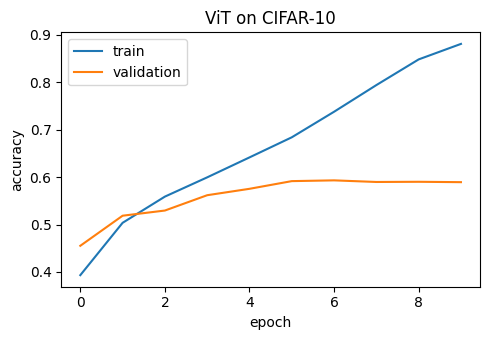

In [13]:
plt.figure(figsize=(5, 3.5))
plt.plot(history["train_acc"], label="train")
plt.plot(history["val_acc"], label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("ViT on CIFAR-10")
plt.legend()
plt.tight_layout()
plt.savefig("assets/vit_accuracy.png", dpi=150)
plt.show()

### 2.4 Where does the `[CLS]` token look?

For 10 validation images, the bottom row shows the attention from `[CLS]` to each patch, averaged over all layers and heads.

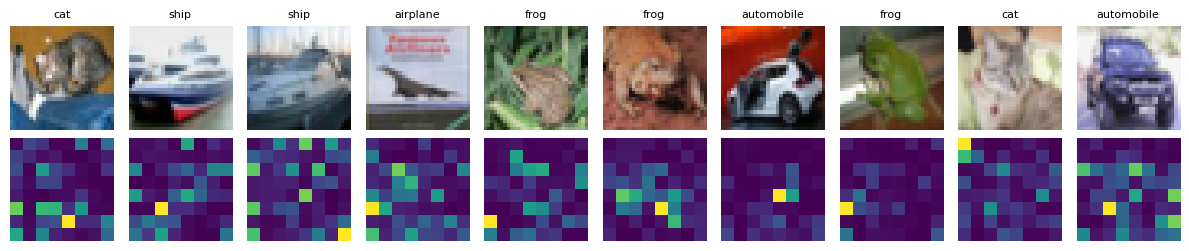

In [14]:
img, labels = next(iter(val_dataloader))
model.eval()
with torch.no_grad():
    _, attns = model(img.to(device), return_attn=True)   # (B, layers, heads, T+1, T+1)

grid = IMG_SIZE // PATCH_SIZE
cls_attn = attns.flatten(1, 2)[:, :, 0, 1:].mean(1).reshape(-1, grid, grid).cpu().numpy()

fig, ax = plt.subplots(2, 10, figsize=(12, 2.6))
for i in range(10):
    ax[0, i].imshow(inv_transform(img[i]))
    ax[0, i].set_title(train_dataset.classes[int(labels[i])], fontsize=8)
    ax[1, i].imshow(cls_attn[i])
    ax[0, i].axis("off")
    ax[1, i].axis("off")
plt.tight_layout()
plt.savefig("assets/vit_attention.png", dpi=150)
plt.show()

## 3. Dialogue GPT on Tiny Shakespeare

A word-level, decoder-only language model. Each training example is one speech, for example `KING RICHARD III: Say that I did all this for love of her.`

In [15]:
if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "input.txt")

with open("input.txt") as f:
    raw_text = f.read()
all_dialogues = raw_text.split("\n\n")
print(f"{len(all_dialogues):,} dialogue snippets")

import nltk
from nltk.tokenize import word_tokenize
nltk.download("punkt_tab", quiet=True)

7,222 dialogue snippets


True

### 3.1 Tokenizer

In [16]:
class MyTokenizer:
    # word-level tokenizer with <START>, <PAD> and <UNK> special tokens.
    def __init__(self, raw_text: str):
        self.start, self.pad, self.unk = "<START>", "<PAD>", "<UNK>"
        vocab = np.unique(word_tokenize(raw_text))
        self.vocab = np.concatenate([np.array([self.start, self.pad, self.unk]), vocab])
        self.tok_to_id = {w: i for i, w in enumerate(self.vocab)}
        self.vocab_size = len(self.vocab)

    def encode(self, s: str) -> torch.Tensor:
        # string -> tensor of token ids, beginning with <START>
        unk = self.tok_to_id[self.unk]
        ids = [self.tok_to_id[self.start]] + [self.tok_to_id.get(w, unk) for w in word_tokenize(s)]
        return torch.tensor(ids)

    def decode(self, toks: torch.Tensor) -> str:
        return " ".join(self.vocab[i] for i in toks.tolist())

    def pad_examples(self, tok_list: List[torch.Tensor]) -> torch.Tensor:
        # right-pad a list of id tensors to a common length
        return nn.utils.rnn.pad_sequence(tok_list, batch_first=True, padding_value=self.tok_to_id[self.pad])


tok = MyTokenizer(raw_text)
print("Vocabulary size:", tok.vocab_size)

dec = tok.decode(tok.encode("KING RICHARD III:\nSay that I did all this for love of her."))
assert dec == "<START> KING RICHARD III : Say that I did all this for love of her ."
print(dec)

Vocabulary size: 14213
<START> KING RICHARD III : Say that I did all this for love of her .


### 3.2 Dataset

In [17]:
MAX_N = 200  # maximum tokens per example


class DialogueDataset(torch.utils.data.Dataset):
    def __init__(self, tokenizer: MyTokenizer, lines: List[str], max_N: int):
        self.tokenizer, self.lines, self.max_N = tokenizer, lines, max_N

    def __len__(self) -> int:
        return len(self.lines)

    def __getitem__(self, idx: int) -> torch.Tensor:
        return self.tokenizer.encode(self.lines[idx])[: self.max_N]


def collate_fn(examples: List[torch.Tensor]):
    # pad a batch; input_mask is 1 for real tokens and 0 for padding
    input_ids = tok.pad_examples(examples)
    input_mask = (input_ids != tok.tok_to_id[tok.pad]).float()
    return {"input_ids": input_ids, "input_mask": input_mask}


ds = DialogueDataset(tok, all_dialogues, max_N=MAX_N)
training_dl = torch.utils.data.DataLoader(ds, batch_size=64, shuffle=True, collate_fn=collate_fn)

### 3.3 Model

Token embeddings plus learned positional embeddings go through the transformer with a **causal mask** (lower-triangular, so token $i$ only sees tokens $\le i$). Then a linear head produces next-token logits.

In [18]:
class DialogueGPT(nn.Module):
    def __init__(self, vocab_size: int, max_N: int, dim: int, attn_dim: int, mlp_dim: int,
                 num_heads: int, num_layers: int):
        super().__init__()
        self.max_N = max_N
        self.token_E = nn.Embedding(vocab_size, dim)   # one learned vector per word
        self.pos_E = nn.Embedding(max_N, dim)          # one learned vector per position
        self.transformer = Transformer(dim=dim, attn_dim=attn_dim, mlp_dim=mlp_dim,
                                       num_heads=num_heads, num_layers=num_layers)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, vocab_size))

    def forward(self, input_ids: torch.Tensor, return_attn: bool = False):
        # input_ids: (B, T) -> logits (B, T, vocab_size)
        B, T = input_ids.shape
        positions = torch.arange(T, device=input_ids.device)
        embs = self.token_E(input_ids) + self.pos_E(positions)          # (B, T, dim)
        # all tokends only depend on themselve and the tokens before, and thus lower-trianglar causal attention mask
        causal_mask = torch.tril(torch.ones(T, T, device=input_ids.device)).expand(B, T, T)
        x, alphas = self.transformer(embs, attn_mask=causal_mask, return_attn=return_attn)
        return self.head(x), alphas

    @torch.no_grad()
    def generate(self, input_ids: torch.Tensor, num_tokens: int, temperature: float = 0.0) -> torch.Tensor:
        # Extend input_ids (1, T) by num_tokens.
        # temperature = 0 is greedy decoding; temperature > 0 samples from softmax(logits / temperature).
        for _ in range(num_tokens):
            logits, _ = self(input_ids[:, -self.max_N:])   # crop to the positional-embedding range
            logits = logits[:, -1, :]
            if temperature > 0:
                next_tok = torch.multinomial(torch.softmax(logits / temperature, dim=-1), 1)
            else:
                next_tok = logits.argmax(dim=-1, keepdim=True)
            input_ids = torch.cat([input_ids, next_tok], dim=1)
        return input_ids

### 3.4 Language-model loss

The logits at position $t$ predict token $t+1$. The loss is the cross-entropy averaged over non-padding target tokens.

In [19]:
class DialogueLoss(nn.Module):
    def forward(self, logits: torch.Tensor, input_ids: torch.Tensor, inp_mask: torch.Tensor) -> torch.Tensor:
        V = logits.shape[-1]
        pred = logits[:, :-1].reshape(-1, V)        # drop the last position (no next token)
        target = input_ids[:, 1:].reshape(-1)       # drop <START> (never predicted)
        mask = inp_mask[:, 1:].reshape(-1).float()
        # cross entropy computes the log sum exponent corresponding to the target
        losses = F.cross_entropy(pred, target, reduction="none")
        return (losses * mask).sum() / mask.sum()

### 3.5 Training

In [20]:
NUM_EPOCHS = 80   # about 25 minutes on a T4 GPU

model = DialogueGPT(vocab_size=tok.vocab_size, max_N=MAX_N, dim=128, attn_dim=64, mlp_dim=128,
                    num_heads=3, num_layers=6).to(device)
criterion = DialogueLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

prompt = tok.encode("").unsqueeze(0).to(device)   # just the <START> token
loss_history = []
for epoch in range(NUM_EPOCHS):
    model.train()
    loss_meter = AverageMeter()
    for batch in tqdm(training_dl, leave=False, desc=f"epoch {epoch}"):
        inp_ids = batch["input_ids"].to(device)
        inp_mask = batch["input_mask"].to(device)
        optimizer.zero_grad()
        logits, _ = model(inp_ids)
        loss = criterion(logits, inp_ids, inp_mask)
        loss.backward()
        optimizer.step()
        loss_meter.update(loss.item(), len(inp_ids))
    scheduler.step()
    loss_history.append(loss_meter.calculate())

    if epoch % 10 == 0 or epoch == NUM_EPOCHS - 1:
        model.eval()
        sample = tok.decode(model.generate(prompt, 12)[0].cpu())
        print(f"Epoch {epoch:2d} | loss {loss_history[-1]:.3f} | {sample}")

Parameters: 4,472,325


epoch 0:   0%|          | 0/113 [00:00<?, ?it/s]

Epoch  0 | loss 8.361 | <START> : : : , , , , , , , , ,


epoch 1:   0%|          | 0/113 [00:00<?, ?it/s]

epoch 2:   0%|          | 0/113 [00:00<?, ?it/s]

epoch 3:   0%|          | 0/113 [00:00<?, ?it/s]

... (80 outputs left out)

epoch 77:   0%|          | 0/113 [00:00<?, ?it/s]

epoch 78:   0%|          | 0/113 [00:00<?, ?it/s]

epoch 79:   0%|          | 0/113 [00:00<?, ?it/s]

Epoch 79 | loss 4.828 | <START> KING RICHARD III : What is the king ? I have a


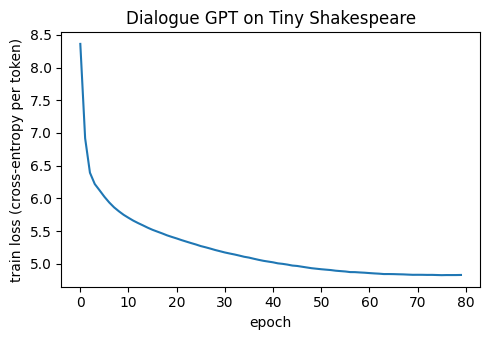

Final loss 4.828  (perplexity ~ 125)


In [21]:
plt.figure(figsize=(5, 3.5))
plt.plot(loss_history)
plt.xlabel("epoch")
plt.ylabel("train loss (cross-entropy per token)")
plt.title("Dialogue GPT on Tiny Shakespeare")
plt.tight_layout()
plt.savefig("assets/gpt_loss.png", dpi=150)
plt.show()
print(f"Final loss {loss_history[-1]:.3f}  (perplexity ~ {math.exp(loss_history[-1]):.0f})")

### 3.6 Generation

Greedy decoding tends to fall into loops ("I am a king . I am a king ..."). Sampling with a temperature gives more varied text.

In [22]:
model.eval()
print("Greedy:\n ", tok.decode(model.generate(prompt, 50)[0].cpu()))
torch.manual_seed(0)
for temp in [0.7, 1.0]:
    print(f"\nTemperature {temp}:\n ", tok.decode(model.generate(prompt, 50, temperature=temp)[0].cpu()))

Greedy:
  <START> KING RICHARD III : What is the king ? I have a king . Now , and I have been a man , And I have been , I have done , and I am not a man , and , and I , And I have I have I

Temperature 0.7:
  <START> DUKE VINCENTIO : How had your grace . We have made a woman : what 's foolish very nature , but no more loves . You , and he 's peril to prison , And , And yet you ? O , in the field , you have been to

Temperature 1.0:
  <START> CORIOLANUS : Love goose ! the royal father on ! Were , a little was need 'd light to church , my fellows with army in print I can not stain , you , didst against the table 'd , But him nothing and covenants us again passion , That
